In [1]:
!pip install scikit-learn torch optuna pandas matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.models import Sequential
import optuna

# Modelo LSTM Unidirecional - Baselines Abordagem A

Para validar a acurácia de um modelo de redes neurais recorrentes e justificar a sua utilização bem como a evolução de sua estrutura, os seguintes testes serão submetidos:

## 1. Auto-previsão do ERA5 ($\text{ERA5} \rightarrow \text{ERA5}$)

O primeiro experimento consiste no teste de auto-previsão autorregressiva de controle (*sanity check*), no qual o modelo é treinado para prever as tendências da própria série temporal da reanálise atmosférica ERA5 (`ws100_era5`).

O objetivo desse teste é **validar o pipeline computacional** e comprovar empiricamente se uma rede LSTM é capaz de aprender a oscilação diurna e a inércia macroatmosférica do modelo global antes de ser submetida a dados ruidosos observados em campo.

A implementação dessa baseline segue as seguintes diretrizes metodológicas:

---

###  Divisão Cronológica do Dataset
O dataset alinhado na escala horária (**Abordagem A**) contém **1.266 pontos coincidentes** obtidos no período de amostragem. Respeitando a ordem temporal cronológica para evitar vazamento de dados (*data leakage*), a base foi dividida em:
* **Treinamento (70%):** ~886 registros (resultando em ~857 sequências de entrada após a aplicação da janela deslizante);
* **Validação (15%):** ~190 registros (aproximadamente 166 sequências para ajuste de hiperparâmetros);
* **Teste (15%):** ~190 registros (aproximadamente 166 sequências para inferência final e avaliação de métricas).

---

### Parametrização da Arquitetura Neural
* **Histórico de Entrada (*Lookback*):** 24 *timestamps* (representando 24 horas de histórico passado na resolução horária) ou **1 passo no horizonte de previsão**;
* **Tamanho do Lote (*Batch Size*):** 32 amostras, valor otimizado para a escala do conjunto de treinamento (~850 sequências);
* **Camada Recorrente:** Camada LSTM com 64 unidades ocultas e função de ativação $\tanh$ para captura de dependências temporais;
* **Regularização:** Camada *Dropout* com taxa de 0,2 (20%) para prevenir sobreajuste (*overfitting*);
* **Processamento Densa Intermediário:** Camada *Dense* com 32 neurônios e função de ativação $\text{ReLU}$;
* **Camada de Saída:**
  * Camada `Dense(1)` para a previsão de passo único ($t + 1\text{h}$);
  * Camada `Dense(6)` para a projeção direta do horizonte multi-passo ($t + 1\text{h}$ a $t + 6\text{h}$).

---

### Otimização e Estratégia de Controle (*Callbacks*)
* **Otimizador e Perda:** Algoritmo *Adam* minimizando a função de perda do Erro Quadrático Médio (MSE);
* **EarlyStopping:** Interrupção automática do treinamento caso a perda de validação (`val_loss`) não apresente melhoria por 7 épocas consecutivas (`patience=7`), restaurando os pesos do melhor estado (`restore_best_weights=True`);
* **ReduceLROnPlateau:** Redução da taxa de aprendizado em 50% (`factor=0.5`) caso a `val_loss` estagne por 3 épocas (`patience=3`), com limite mínimo de $1\times10^{-5}$.






[I 2026-10-19 23:56:59,730] A new study created in memory with name: no-name-225d5819-7065-4687-a4bd-a5b67424a247
[I 2026-10-19 23:57:11,531] Trial 0 finished with value: 0.06890330463647842 and parameters: {'lstm_units': 32, 'dense_units': 16, 'dropout_rate': 0.4, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.06890330463647842.
[I 2026-10-19 23:57:23,179] Trial 1 finished with value: 0.06907454133033752 and parameters: {'lstm_units': 16, 'dense_units': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0016738085788752138, 'batch_size': 64}. Best is trial 0 with value: 0.06890330463647842.
[I 2026-10-19 23:57:40,149] Trial 2 finished with value: 0.14025315642356873 and parameters: {'lstm_units': 32, 'dense_units': 64, 'dropout_rate': 0.1, 'learning_rate': 0.00013492834268013249, 'batch_size': 32}. Best is trial 0 with value: 0.06890330463647842.
[I 2026-10-19 23:58:08,678] Trial 3 finished with value: 0.07479731738567352 and parameters: {'lstm_units

Melhores Hiperparâmetros: {'lstm_units': 32, 'dense_units': 16, 'dropout_rate': 0.1, 'learning_rate': 0.005323617594751502, 'batch_size': 16}
Epoch 1/35
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.3776 - mae: 0.4722 - val_loss: 0.1559 - val_mae: 0.2996 - learning_rate: 0.0053
Epoch 2/35
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1376 - mae: 0.2922 - val_loss: 0.1080 - val_mae: 0.2536 - learning_rate: 0.0053
Epoch 3/35
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0955 - mae: 0.2390 - val_loss: 0.0749 - val_mae: 0.2032 - learning_rate: 0.0053
Epoch 4/35
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0855 - mae: 0.2225 - val_loss: 0.0696 - val_mae: 0.1919 - learning_rate: 0.0053
Epoch 5/35
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0809 - mae: 0.2196 - val_loss: 0.0775 - val_mae: 0.2034 - learning_rate: 0.0053
Epoch 6/35
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0735 - mae: 0.2071 - val_loss: 0.0717 - val_mae: 0.1925 - learning_rate: 0.0053
Epoch 7/35
5

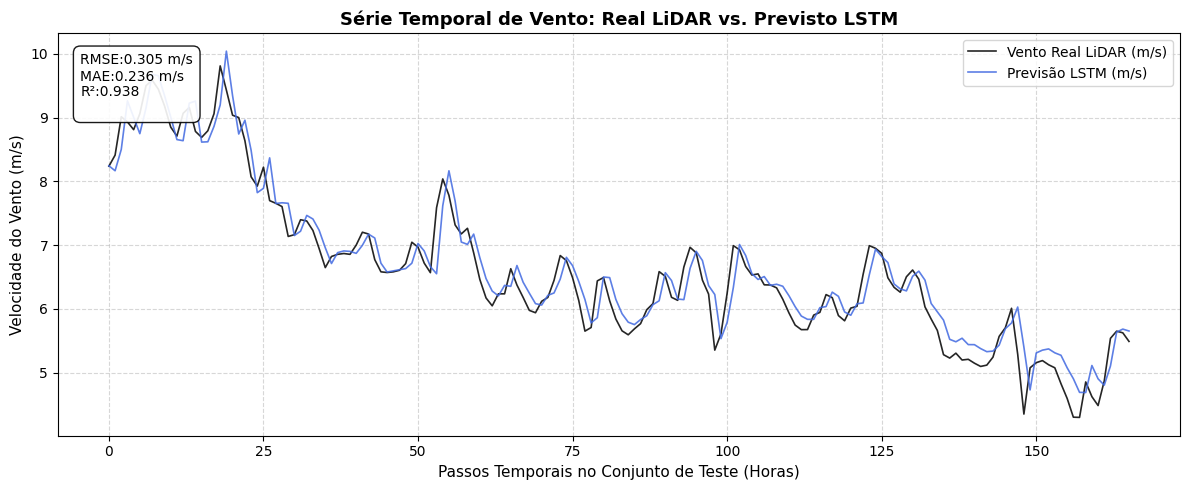

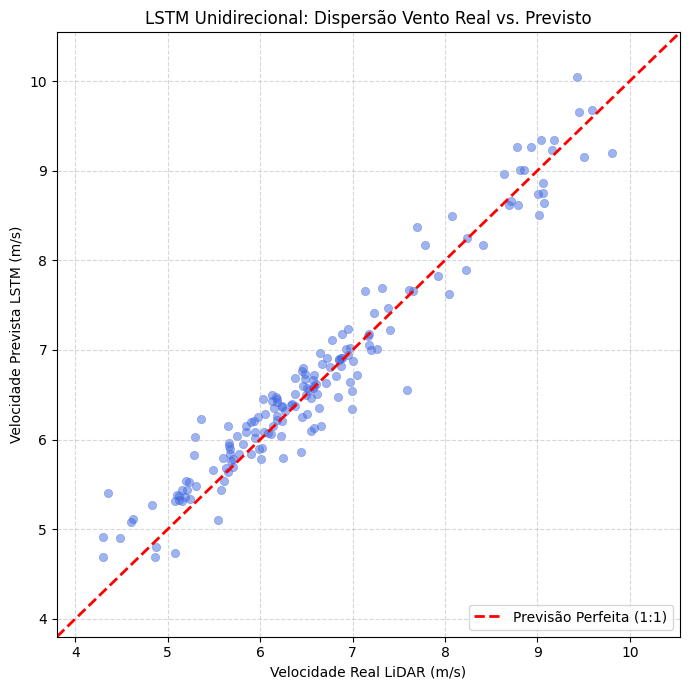

In [3]:
# ==========================================
# 1. CARREGAMENTO E DIVISÃO TEMPORAL
# ==========================================
df = pd.read_parquet("data/approach_a.parquet")

features = ["ws100_era5"]
target = "ws100_era5"

n = len(df)
train_df = df.iloc[: int(n * 0.7)]
val_df = df.iloc[int(n * 0.7) : int(n * 0.85)]
test_df = df.iloc[int(n * 0.85) :]

# ==========================================
# 2. NORMALIZAÇÃO SEPARADA (X e Y)
# ==========================================
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_raw = scaler_x.fit_transform(train_df[features])
y_train_raw = scaler_y.fit_transform(train_df[[target]])

X_val_raw = scaler_x.transform(val_df[features])
y_val_raw = scaler_y.transform(val_df[[target]])

X_test_raw = scaler_x.transform(test_df[features])
y_test_raw = scaler_y.transform(test_df[[target]])

# ==========================================
# 3. JANELA DESLIZANTE (SLIDING WINDOW)
# ==========================================
def create_sequences(X_data, y_data, lookback=24):
  X_out, y_out = [], []
  for i in range(len(X_data) - lookback):
    X_out.append(X_data[i : i + lookback, :])
    y_out.append(y_data[i + lookback, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 24
X_train, y_train = create_sequences(X_train_raw, y_train_raw, LOOKBACK)
X_val, y_val = create_sequences(X_val_raw, y_val_raw, LOOKBACK)
X_test, y_test = create_sequences(X_test_raw, y_test_raw, LOOKBACK)

# ==========================================
# 4. MODELO LSTM UNIDIRECIONAL COM OPTUNA
# ==========================================
def build_and_evaluate_model(trial, X_train, y_train, X_val, y_val):
  # 1. Definição do Espaço de Busca (Hyperparameter Search Space)
  lstm_units = trial.suggest_categorical('lstm_units', [16, 32, 64, 128])
  dense_units = trial.suggest_categorical('dense_units', [16, 32, 64])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.4, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

  # 2. Definição do Modelo dentro da Função do Trial
  model = Sequential(
      [
          Input(
              shape=(X_train.shape[1], X_train.shape[2])
          ),
          LSTM(lstm_units, activation="tanh"),
          Dropout(dropout_rate),
          Dense(dense_units, activation="relu"),
          Dense(1),
      ]
  )
  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])

  # Callbacks para otimização de treinamento
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=35,
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

# ==========================================
# 5. TREINAMENTO DO MODELO FINAL COM OS MELHORES PARÂMETROS
# ==========================================
best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation="tanh"),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation="relu"),
    Dense(1),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=35,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

y_pred_scaled = model.predict(X_test)

y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred = scaler_y.inverse_transform(y_pred_scaled).flatten()

rmse = np.sqrt(mean_squared_error(y_real, y_pred))
mae = mean_absolute_error(y_real, y_pred)
r2 = r2_score(y_real, y_pred)

print(f"--- Métricas Globais do Conjunto de Teste ---")
print(
    f"RMSE: {rmse:.3f} m/s | MAE: {mae:.3f} m/s | R²: {r2:.3f} "
)

# ==========================================
# 6. VISUALIZAÇÃO DA SÉRIE TEMPORAL (REAL VS PREVISTO)
# ==========================================
plt.figure(figsize=(12, 5))

# Plotagem das séries temporais
plt.plot(
    y_real,
    label="Vento Real LiDAR (m/s)",
    color="black",
    linewidth=1.2,
    alpha=0.85,
)
plt.plot(
    y_pred,
    label="Previsão LSTM (m/s)",
    color="royalblue",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    "Série Temporal de Vento: Real LiDAR vs. Previsto LSTM",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Passos Temporais no Conjunto de Teste (Horas)", fontsize=11)
plt.ylabel("Velocidade do Vento (m/s)", fontsize=11)
plt.legend(loc="upper right", frameon=True, facecolor="white")
plt.grid(True, linestyle="--", alpha=0.5)

# Caixa informativa de métricas
metrics_text = (
    f"RMSE:{rmse:.3f} m/s\nMAE:{mae:.3f} m/s\nR²:{r2:.3f}\n"
)
plt.gca().text(
    0.02,
    0.95,
    metrics_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9),
)

plt.tight_layout()
plt.show()

# ==========================================
# 7. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real, y=y_pred, alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)

plt.title("LSTM Unidirecional: Dispersão Vento Real vs. Previsto", fontsize=12)
plt.xlabel("Velocidade Real LiDAR (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### Ampliação do Horizonte para 6 passos:



[I 2026-10-20 00:12:09,633] A new study created in memory with name: no-name-a4126ea8-c7e9-4aee-83a0-5f1d27784143


Formato de X_train (Amostras, Histórico, Atributos): (857, 24, 1)
Formato de y_train (Amostras, Horizonte Futuro): (857, 6)



[I 2026-10-20 00:12:17,089] Trial 0 finished with value: 0.551409125328064 and parameters: {'lstm_units': 32, 'dense_units': 16, 'dropout_rate': 0.4, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.551409125328064.
[I 2026-10-20 00:12:23,492] Trial 1 finished with value: 0.5247361660003662 and parameters: {'lstm_units': 16, 'dense_units': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0016738085788752138, 'batch_size': 64}. Best is trial 1 with value: 0.5247361660003662.
[I 2026-10-20 00:12:33,031] Trial 2 finished with value: 0.6320677995681763 and parameters: {'lstm_units': 32, 'dense_units': 64, 'dropout_rate': 0.1, 'learning_rate': 0.00013492834268013249, 'batch_size': 32}. Best is trial 1 with value: 0.5247361660003662.
[I 2026-10-20 00:12:46,583] Trial 3 finished with value: 0.5564402937889099 and parameters: {'lstm_units': 64, 'dense_units': 32, 'dropout_rate': 0.4, 'learning_rate': 0.00032927591344236165, 'batch_size': 16}. Best is trial 1 

Melhores Hiperparâmetros: {'lstm_units': 64, 'dense_units': 64, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.008420978206752958, 'batch_size': 16}
Epoch 1/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.4988 - mae: 0.5465 - val_loss: 0.4940 - val_mae: 0.5499 - learning_rate: 0.0084
Epoch 2/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.4250 - mae: 0.5045 - val_loss: 0.5600 - val_mae: 0.5770 - learning_rate: 0.0084
Epoch 3/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.3787 - mae: 0.4720 - val_loss: 0.4815 - val_mae: 0.5478 - learning_rate: 0.0084
Epoch 4/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.3884 - mae: 0.4779 - val_loss: 0.5105 - val_mae: 0.5687 - learning_rate: 0.0084
Epoch 5/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.3547 - mae: 0.4580 - val_loss: 0.3984 - val_mae: 0.4752 - learning_rate: 0.0084
Epoch 6/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.3256 - mae: 0.4368 - val_loss: 0.3951 - val_mae: 0.4885 - learning_rate: 0.0

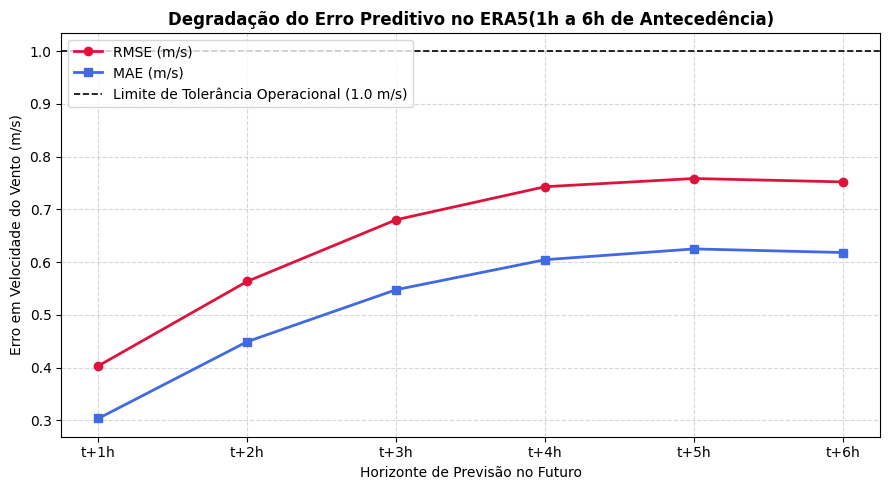

In [6]:
# ==========================================
# 9. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP (1 passo -> 6 passos)
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=24, horizon=6):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (6) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 24  # 24 horas de histórico passado
HORIZON = 6  # 6 passos de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")

# ==========================================
# 10. MODELO LSTM MULTI-STEP (Dense de Saída = 6)
# ==========================================
def build_and_evaluate_model(trial, X_train, y_train, X_val, y_val):
  # 1. Definição do Espaço de Busca (Hyperparameter Search Space)
  lstm_units = trial.suggest_categorical('lstm_units', [16, 32, 64, 128])
  dense_units = trial.suggest_categorical('dense_units', [16, 32, 64])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.4, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

  model = Sequential([
      Input(shape=(X_train.shape[1], X_train.shape[2])),
      LSTM(lstm_units, activation='tanh'),
      Dropout(dropout_rate),
      Dense(dense_units, activation='relu'),
      Dense(HORIZON),
  ])

  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

  # Callbacks de controle
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=15,  # Reduzido levemente para acelerar a otimização no Optuna
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

# ==========================================
# 11. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
# Para inferência, precisamos instanciar e treinar o modelo final com os melhores hiperparâmetros antes do predict
best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation='tanh'),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation='relu'),
    Dense(HORIZON),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

y_pred_scaled = model.predict(X_test)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 12. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t+{step+1}h -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 13. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"t+{i+1}h" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 2. Previsão do Vento LiDAR Filtrado ($\text{ws100_lidar_clean} \rightarrow \text{ws100_lidar}$)

O segundo experimento consiste no teste autorregressivo de inércia com sinal suavizado, no qual a rede neural é treinada para prever a velocidade real e instantânea do vento medida pelo LiDAR (`ws100_lidar`) utilizando como entrada a série temporal filtrada pela Transformada de Wavelet da Abordagem A (`ws100_lidar_clean`).

O objetivo desse teste é **avaliar a capacidade da LSTM em aprender a dinâmica de macroescala e a inércia física do vento real em escala horária** após a atenuação de ruídos estocásticos de alta frequência (turbulência), verificando se o *denoising* por Wavelet (`sym18`, nível 2) melhora a estabilidade preditiva do modelo.

A implementação dessa *baseline* segue as seguintes diretrizes metodológicas:

---

###  Divisão Cronológica do Dataset
O dataset alinhado na escala horária (**Abordagem A**) contém **1.266 pontos coincidentes** entre o sensor e a reanálise. Respeitando a ordem temporal cronológica para evitar vazamento de dados (*data leakage*), a base foi dividida em:
* **Treinamento (70%):** ~886 registros (resultando em ~857 sequências de entrada após a aplicação da janela deslizante);
* **Validação (15%):** ~190 registros (aproximadamente 166 sequências para ajuste de hiperparâmetros);
* **Teste (15%):** ~190 registros (aproximadamente 166 sequências para inferência final e avaliação de métricas).

---

### Parametrização da Arquitetura Neural
* **Histórico de Entrada (*Lookback*):** 24 *timestamps* (representando 24 horas de histórico passado na resolução horária) ou **1 passo no horizonte de previsão**;
* **Tamanho do Lote (*Batch Size*):** 32 amostras, valor otimizado para a escala do conjunto de treinamento (~850 sequências);
* **Camada Recorrente:** Camada LSTM com 64 unidades ocultas e função de ativação $\tanh$ para captura das dependências temporais do vento local;
* **Regularização:** Camada *Dropout* com taxa de 0,2 (20%) para prevenir sobreajuste (*overfitting*);
* **Processamento Densa Intermediário:** Camada *Dense* com 32 neurônios e função de ativação $\text{ReLU}$;
* **Camada de Saída:**
  * Camada `Dense(1)` para a previsão de passo único ($t + 1\text{h}$);
  * Camada `Dense(6)` para a projeção direta do horizonte multi-passo ($t + 1\text{h}$ a $t + 6\text{h}$).

---

### Otimização e Estratégia de Controle (*Callbacks*)
* **Otimizador e Perda:** Algoritmo *Adam* minimizando a função de perda do Erro Quadrático Médio (MSE);
* **EarlyStopping:** Interrupção automática do treinamento caso a perda de validação (`val_loss`) não apresente melhoria por 7 épocas consecutivas (`patience=7`), restaurando os pesos do melhor estado (`restore_best_weights=True`);
* **ReduceLROnPlateau:** Redução da taxa de aprendizado em 50% (`factor=0.5`) caso a `val_loss` estagne por 3 épocas (`patience=3`), com limite mínimo de $1\times10^{-5}$.

[I 2026-10-20 00:22:33,370] A new study created in memory with name: no-name-83860746-fd76-44bc-8b43-0095ec774b6e
[I 2026-10-20 00:22:47,495] Trial 0 finished with value: 0.17751088738441467 and parameters: {'lstm_units': 32, 'dense_units': 16, 'dropout_rate': 0.4, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.17751088738441467.
[I 2026-10-20 00:22:59,369] Trial 1 finished with value: 0.18136149644851685 and parameters: {'lstm_units': 16, 'dense_units': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0016738085788752138, 'batch_size': 64}. Best is trial 0 with value: 0.17751088738441467.
[I 2026-10-20 00:23:19,142] Trial 2 finished with value: 0.2777356207370758 and parameters: {'lstm_units': 32, 'dense_units': 64, 'dropout_rate': 0.1, 'learning_rate': 0.00013492834268013249, 'batch_size': 32}. Best is trial 0 with value: 0.17751088738441467.
[I 2026-10-20 00:23:47,172] Trial 3 finished with value: 0.17853662371635437 and parameters: {'lstm_units'

Melhores Hiperparâmetros: {'lstm_units': 32, 'dense_units': 16, 'dropout_rate': 0.4, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}
Epoch 1/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.7317 - mae: 0.6607 - val_loss: 0.5954 - val_mae: 0.6080 - learning_rate: 0.0016
Epoch 2/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5579 - mae: 0.5756 - val_loss: 0.4728 - val_mae: 0.5104 - learning_rate: 0.0016
Epoch 3/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.5134 - mae: 0.5498 - val_loss: 0.4198 - val_mae: 0.4830 - learning_rate: 0.0016
Epoch 4/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4457 - mae: 0.5128 - val_loss: 0.3763 - val_mae: 0.4478 - learning_rate: 0.0016
Epoch 5/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.4151 - mae: 0.4970 - val_loss: 0.3436 - val_mae: 0.4277 - learning_rate: 0.0016
Epoch 6/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.3845 - mae: 0.4793 - val_loss: 0.3048 - val_mae: 0.3943 - learning_rate: 0.0016
Epoch 7/35


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
--- Métricas Globais do Conjunto de Teste ---
RMSE: 0.507 m/s | MAE: 0.389 m/s | R²: 0.907 


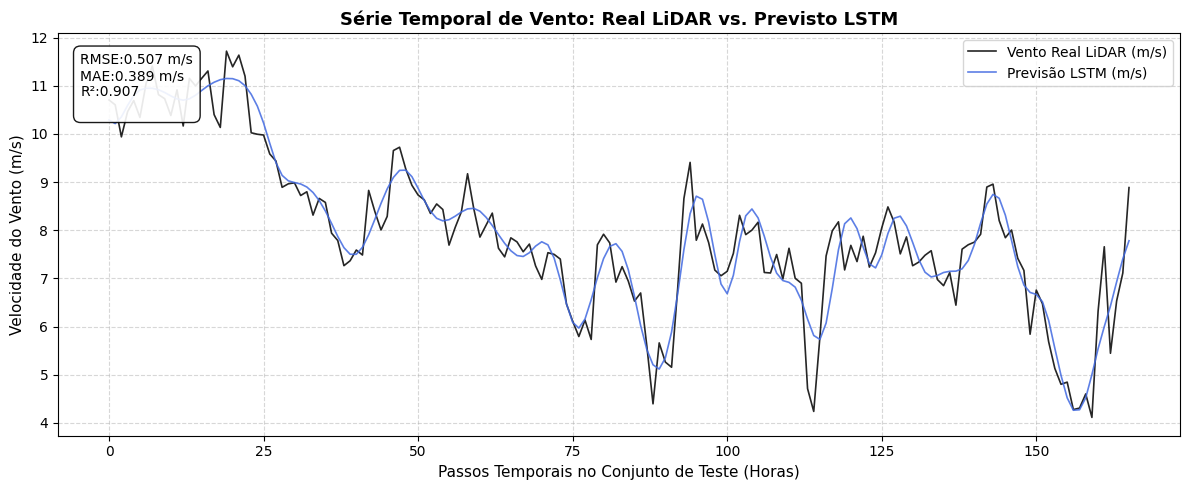

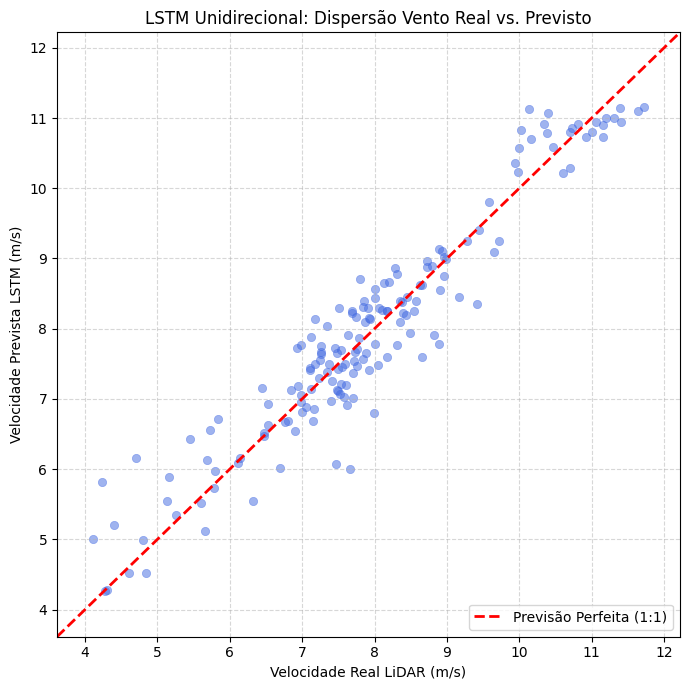

In [8]:
# ==========================================
# 1. CARREGAMENTO E DIVISÃO TEMPORAL
# ==========================================
df = pd.read_parquet("data/approach_a.parquet")

features = ["ws100_lidar_clean"]
target = "ws100_lidar"

n = len(df)
train_df = df.iloc[: int(n * 0.7)]
val_df = df.iloc[int(n * 0.7) : int(n * 0.85)]
test_df = df.iloc[int(n * 0.85) :]

# ==========================================
# 2. NORMALIZAÇÃO SEPARADA (X e Y)
# ==========================================
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_raw = scaler_x.fit_transform(train_df[features])
y_train_raw = scaler_y.fit_transform(train_df[[target]])

X_val_raw = scaler_x.transform(val_df[features])
y_val_raw = scaler_y.transform(val_df[[target]])

X_test_raw = scaler_x.transform(test_df[features])
y_test_raw = scaler_y.transform(test_df[[target]])

# ==========================================
# 3. JANELA DESLIZANTE (SLIDING WINDOW)
# ==========================================
def create_sequences(X_data, y_data, lookback=24):
  X_out, y_out = [], []
  for i in range(len(X_data) - lookback):
    X_out.append(X_data[i : i + lookback, :])
    y_out.append(y_data[i + lookback, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 24
X_train, y_train = create_sequences(X_train_raw, y_train_raw, LOOKBACK)
X_val, y_val = create_sequences(X_val_raw, y_val_raw, LOOKBACK)
X_test, y_test = create_sequences(X_test_raw, y_test_raw, LOOKBACK)

# ==========================================
# 4. MODELO LSTM UNIDIRECIONAL COM OPTUNA
# ==========================================
def build_and_evaluate_model(trial, X_train, y_train, X_val, y_val):
  # 1. Definição do Espaço de Busca (Hyperparameter Search Space)
  lstm_units = trial.suggest_categorical('lstm_units', [16, 32, 64, 128])
  dense_units = trial.suggest_categorical('dense_units', [16, 32, 64])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.4, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

  # 2. Definição do Modelo dentro da Função do Trial
  model = Sequential(
      [
          Input(
              shape=(X_train.shape[1], X_train.shape[2])
          ),
          LSTM(lstm_units, activation="tanh"),
          Dropout(dropout_rate),
          Dense(dense_units, activation="relu"),
          Dense(1),
      ]
  )
  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])

  # Callbacks para otimização de treinamento
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=35,
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

# ==========================================
# 5. TREINAMENTO DO MODELO FINAL COM OS MELHORES PARÂMETROS
# ==========================================
best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation="tanh"),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation="relu"),
    Dense(1),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=35,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

y_pred_scaled = model.predict(X_test)

y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred = scaler_y.inverse_transform(y_pred_scaled).flatten()

rmse = np.sqrt(mean_squared_error(y_real, y_pred))
mae = mean_absolute_error(y_real, y_pred)
r2 = r2_score(y_real, y_pred)

print(f"--- Métricas Globais do Conjunto de Teste ---")
print(
    f"RMSE: {rmse:.3f} m/s | MAE: {mae:.3f} m/s | R²: {r2:.3f} "
)

# ==========================================
# 6. VISUALIZAÇÃO DA SÉRIE TEMPORAL (REAL VS PREVISTO)
# ==========================================
plt.figure(figsize=(12, 5))

# Plotagem das séries temporais
plt.plot(
    y_real,
    label="Vento Real LiDAR (m/s)",
    color="black",
    linewidth=1.2,
    alpha=0.85,
)
plt.plot(
    y_pred,
    label="Previsão LSTM (m/s)",
    color="royalblue",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    "Série Temporal de Vento: Real LiDAR vs. Previsto LSTM",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Passos Temporais no Conjunto de Teste (Horas)", fontsize=11)
plt.ylabel("Velocidade do Vento (m/s)", fontsize=11)
plt.legend(loc="upper right", frameon=True, facecolor="white")
plt.grid(True, linestyle="--", alpha=0.5)

# Caixa informativa de métricas
metrics_text = (
    f"RMSE:{rmse:.3f} m/s\nMAE:{mae:.3f} m/s\nR²:{r2:.3f}\n"
)
plt.gca().text(
    0.02,
    0.95,
    metrics_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9),
)

plt.tight_layout()
plt.show()

# ==========================================
# 7. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real, y=y_pred, alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)

plt.title("LSTM Unidirecional: Dispersão Vento Real vs. Previsto", fontsize=12)
plt.xlabel("Velocidade Real LiDAR (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### Ampliação do Horizonte para 6 passos:



[I 2026-10-20 00:31:31,586] A new study created in memory with name: no-name-925446fc-aa67-4550-8d06-194f2e85d832


Formato de X_train (Amostras, Histórico, Atributos): (857, 24, 1)
Formato de y_train (Amostras, Horizonte Futuro): (857, 6)



[I 2026-10-20 00:31:39,110] Trial 0 finished with value: 0.5616682171821594 and parameters: {'lstm_units': 32, 'dense_units': 16, 'dropout_rate': 0.4, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.5616682171821594.
[I 2026-10-20 00:31:45,311] Trial 1 finished with value: 0.6024274826049805 and parameters: {'lstm_units': 16, 'dense_units': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0016738085788752138, 'batch_size': 64}. Best is trial 0 with value: 0.5616682171821594.
[I 2026-10-20 00:31:53,758] Trial 2 finished with value: 0.6723745465278625 and parameters: {'lstm_units': 32, 'dense_units': 64, 'dropout_rate': 0.1, 'learning_rate': 0.00013492834268013249, 'batch_size': 32}. Best is trial 0 with value: 0.5616682171821594.
[I 2026-10-20 00:32:07,358] Trial 3 finished with value: 0.6503396034240723 and parameters: {'lstm_units': 64, 'dense_units': 32, 'dropout_rate': 0.4, 'learning_rate': 0.00032927591344236165, 'batch_size': 16}. Best is trial 

Melhores Hiperparâmetros: {'lstm_units': 128, 'dense_units': 16, 'dropout_rate': 0.1, 'learning_rate': 0.005962761966782455, 'batch_size': 16}
Epoch 1/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.7168 - mae: 0.6562 - val_loss: 0.5987 - val_mae: 0.5712 - learning_rate: 0.0060
Epoch 2/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.5549 - mae: 0.5594 - val_loss: 0.4908 - val_mae: 0.5294 - learning_rate: 0.0060
Epoch 3/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.4647 - mae: 0.5140 - val_loss: 0.4357 - val_mae: 0.4972 - learning_rate: 0.0060
Epoch 4/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.4332 - mae: 0.4939 - val_loss: 0.4274 - val_mae: 0.4917 - learning_rate: 0.0060
Epoch 5/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.4103 - mae: 0.4820 - val_loss: 0.4191 - val_mae: 0.4931 - learning_rate: 0.0060
Epoch 6/15
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.3971 - mae: 0.4724 - val_loss: 0.3796 - val_mae: 0.4594 - learning_rate: 0.0060
Epoch 7/15


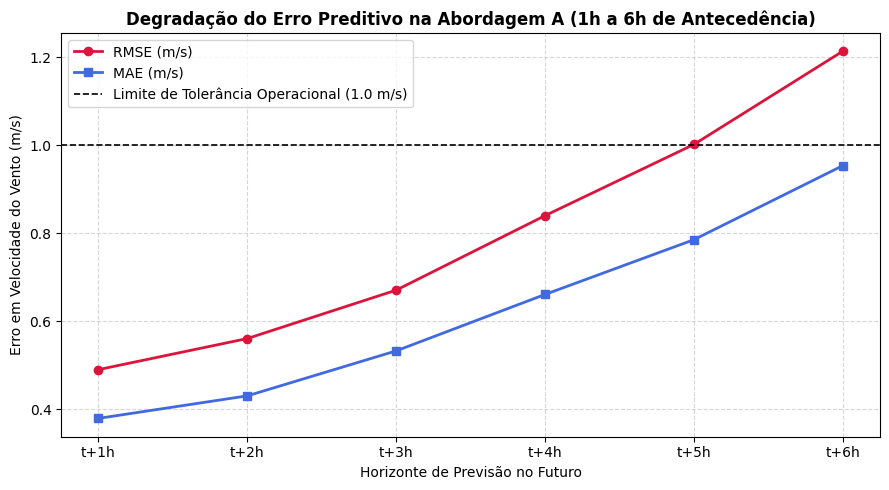

In [10]:
# ==========================================
# 8. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP (1h -> 6h)
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=24, horizon=6):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (6) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 24  # 24 horas de histórico passado
HORIZON = 6  # 6 horas de previsão futura

# Chamada das sequências adicionada para corrigir o erro de dimensões
X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")

def build_and_evaluate_model(trial, X_train, y_train, X_val, y_val):
  # 1. Definição do Espaço de Busca (Hyperparameter Search Space)
  lstm_units = trial.suggest_categorical('lstm_units', [16, 32, 64, 128])
  dense_units = trial.suggest_categorical('dense_units', [16, 32, 64])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.4, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

  model = Sequential([
      Input(shape=(X_train.shape[1], X_train.shape[2])),
      LSTM(lstm_units, activation='tanh'),
      Dropout(dropout_rate),
      Dense(dense_units, activation='relu'),
      Dense(HORIZON),
  ])

  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

  # Callbacks de controle
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=15,  # Reduzido levemente para acelerar a otimização no Optuna
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

# ==========================================
# 9. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
# Para inferência, precisamos instanciar e treinar o modelo final com os melhores hiperparâmetros antes do predict
best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation='tanh'),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation='relu'),
    Dense(HORIZON),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

y_pred_scaled = model.predict(X_test)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)

# ==========================================
# 10. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP: ABORDAGEM A (HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t+{step+1}h -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 11. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"t+{i+1}h" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo na Abordagem A (1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 3. Previsão com Vetor Misto
####($\text{ws100_lidar_clean} + \text{ws100_era5} \rightarrow \text{ws100_lidar}$)

O terceiro experimento consiste no teste de **fusão multivariada de dados**, no qual a rede neural é alimentada simultaneamente por duas fontes de informação com escalas físicas e dinâmicas distintas: a série temporal alinhada do LiDAR/ERA5 filtrada por Wavelet (`ws100_lidar_clean`) e a reanálise atmosférica global do ERA5 (`ws100_era5`), tendo como alvo a velocidade real e instantânea do vento medida pelo anemômetro a laser (`ws100_lidar`).

O objetivo desse teste é **avaliar a capacidade do modelo em realizar o acoplamento de atributos de macroescala (~31 km) e microescala pontual**, investigando se a inclusão da tendência atmosférica global da reanálise melhora a acurácia da previsão ou se introduz ruído de otimização na atualização dos pesos da rede.

A implementação dessa *baseline* segue as seguintes diretrizes metodológicas:

---

###  Divisão Cronológica do Dataset
O dataset alinhado na escala horária (**Abordagem A**) contém **1.266 pontos coincidentes** entre o sensor e a reanálise. Respeitando a ordem temporal cronológica para evitar vazamento de dados (*data leakage*), a base foi dividida em:
* **Treinamento (70%):** ~886 registros (resultando em ~857 sequências de entrada com vetor bidimensional de atributos após a aplicação da janela deslizante);
* **Validação (15%):** ~190 registros (aproximadamente 166 sequências para ajuste de hiperparâmetros);
* **Teste (15%):** ~190 registros (aproximadamente 166 sequências para inferência final e avaliação de métricas).

---

### Parametrização da Arquitetura Neural
* **Histórico de Entrada (*Lookback*):** 24 *timestamps* (representando 24 horas de histórico passado na resolução horária, contendo as 2 variáveis de entrada concatenadas em cada passo);
* **Tamanho do Lote (*Batch Size*):** 32 amostras, valor otimizado para a escala do conjunto de treinamento (~850 sequências);
* **Camada Recorrente:** Camada LSTM com 64 unidades ocultas e função de ativação $\tanh$ adaptada para o processamento de entradas multivariadas;
* **Regularização:** Camada *Dropout* com taxa de 0,2 (20%) para prevenir sobreajuste (*overfitting*);
* **Processamento Densa Intermediário:** Camada *Dense* com 32 neurônios e função de ativação $\text{ReLU}$;
* **Camada de Saída:**
  * Camada `Dense(1)` para a previsão de passo único ($t + 1\text{h}$);
  * Camada `Dense(6)` para a projeção direta do horizonte multi-passo ($t + 1\text{h}$ a $t + 6\text{h}$).

---

### Otimização e Estratégia de Controle (*Callbacks*)
* **Otimizador e Perda:** Algoritmo *Adam* minimizando a função de perda do Erro Quadrático Médio (MSE);
* **EarlyStopping:** Interrupção automática do treinamento caso a perda de validação (`val_loss`) não apresente melhoria por 7 épocas consecutivas (`patience=7`), restaurando os pesos do melhor estado (`restore_best_weights=True`);
* **ReduceLROnPlateau:** Redução da taxa de aprendizado em 50% (`factor=0.5`) caso a `val_loss` estagne por 3 épocas (`patience=3`), com limite mínimo de $1\times10^{-5}$.

[I 2026-10-20 00:36:49,023] A new study created in memory with name: no-name-c03a797f-fea1-4e83-bdf6-7810e36ac8f2
[I 2026-10-20 00:37:03,179] Trial 0 finished with value: 0.17114140093326569 and parameters: {'lstm_units': 32, 'dense_units': 16, 'dropout_rate': 0.4, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.17114140093326569.
[I 2026-10-20 00:37:15,287] Trial 1 finished with value: 0.17947128415107727 and parameters: {'lstm_units': 16, 'dense_units': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0016738085788752138, 'batch_size': 64}. Best is trial 0 with value: 0.17114140093326569.
[I 2026-10-20 00:37:33,434] Trial 2 finished with value: 0.27561935782432556 and parameters: {'lstm_units': 32, 'dense_units': 64, 'dropout_rate': 0.1, 'learning_rate': 0.00013492834268013249, 'batch_size': 32}. Best is trial 0 with value: 0.17114140093326569.
[I 2026-10-20 00:38:03,480] Trial 3 finished with value: 0.1763353943824768 and parameters: {'lstm_units'

Melhores Hiperparâmetros: {'lstm_units': 32, 'dense_units': 16, 'dropout_rate': 0.4, 'learning_rate': 0.004574042581240098, 'batch_size': 64}
Epoch 1/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - loss: 0.6217 - mae: 0.5987 - val_loss: 0.4420 - val_mae: 0.4857 - learning_rate: 0.0046
Epoch 2/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.4569 - mae: 0.5080 - val_loss: 0.3806 - val_mae: 0.4442 - learning_rate: 0.0046
Epoch 3/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.3876 - mae: 0.4678 - val_loss: 0.3172 - val_mae: 0.4095 - learning_rate: 0.0046
Epoch 4/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.3255 - mae: 0.4356 - val_loss: 0.2652 - val_mae: 0.3730 - learning_rate: 0.0046
Epoch 5/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.2775 - mae: 0.4057 - val_loss: 0.2207 - val_mae: 0.3367 - learning_rate: 0.0046
Epoch 6/35
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.2519 - mae: 0.3793 - val_loss: 0.2177 - val_mae: 0.3403 - learning_rate: 0.0046
Epoch 7/35
1

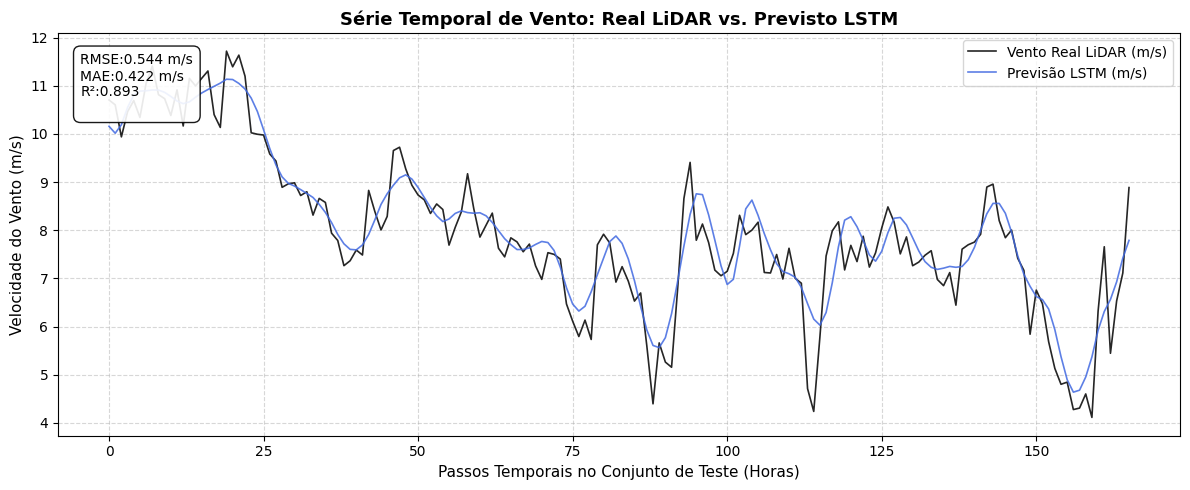

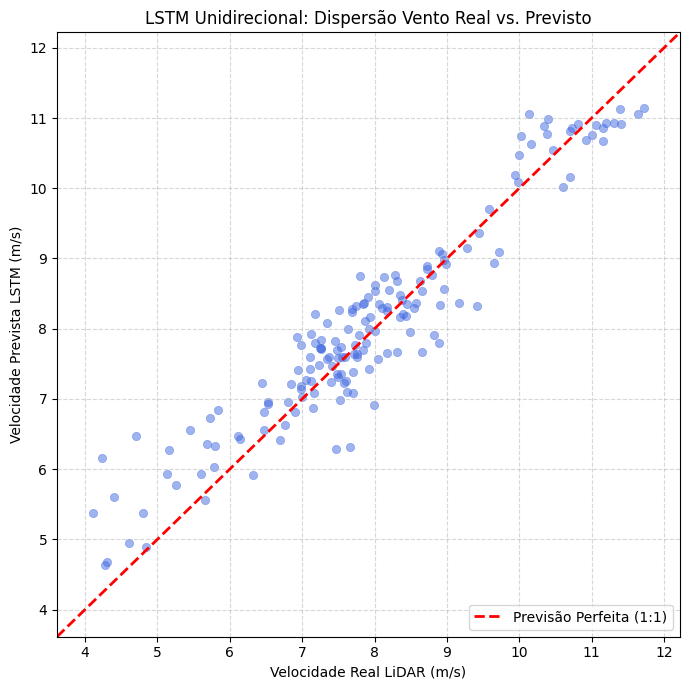

In [11]:
# ==========================================
# 1. CARREGAMENTO E DIVISÃO TEMPORAL
# ==========================================
df = pd.read_parquet("data/approach_a.parquet")

features = ["ws100_lidar_clean", "ws100_era5"]
target = "ws100_lidar"

n = len(df)
train_df = df.iloc[: int(n * 0.7)]
val_df = df.iloc[int(n * 0.7) : int(n * 0.85)]
test_df = df.iloc[int(n * 0.85) :]

# ==========================================
# 2. NORMALIZAÇÃO SEPARADA (X e Y)
# ==========================================
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_raw = scaler_x.fit_transform(train_df[features])
y_train_raw = scaler_y.fit_transform(train_df[[target]])

X_val_raw = scaler_x.transform(val_df[features])
y_val_raw = scaler_y.transform(val_df[[target]])

X_test_raw = scaler_x.transform(test_df[features])
y_test_raw = scaler_y.transform(test_df[[target]])

# ==========================================
# 3. JANELA DESLIZANTE (SLIDING WINDOW)
# ==========================================
def create_sequences(X_data, y_data, lookback=24):
  X_out, y_out = [], []
  for i in range(len(X_data) - lookback):
    X_out.append(X_data[i : i + lookback, :])
    y_out.append(y_data[i + lookback, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 24
X_train, y_train = create_sequences(X_train_raw, y_train_raw, LOOKBACK)
X_val, y_val = create_sequences(X_val_raw, y_val_raw, LOOKBACK)
X_test, y_test = create_sequences(X_test_raw, y_test_raw, LOOKBACK)

# ==========================================
# 4. MODELO LSTM UNIDIRECIONAL COM OPTUNA
# ==========================================
def build_and_evaluate_model(trial, X_train, y_train, X_val, y_val):
  # 1. Definição do Espaço de Busca (Hyperparameter Search Space)
  lstm_units = trial.suggest_categorical('lstm_units', [16, 32, 64, 128])
  dense_units = trial.suggest_categorical('dense_units', [16, 32, 64])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.4, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

  # 2. Definição do Modelo dentro da Função do Trial
  model = Sequential(
      [
          Input(
              shape=(X_train.shape[1], X_train.shape[2])
          ),
          LSTM(lstm_units, activation="tanh"),
          Dropout(dropout_rate),
          Dense(dense_units, activation="relu"),
          Dense(1),
      ]
  )
  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])

  # Callbacks para otimização de treinamento
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=35,
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

# ==========================================
# 5. TREINAMENTO DO MODELO FINAL COM OS MELHORES PARÂMETROS
# ==========================================
best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation="tanh"),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation="relu"),
    Dense(1),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=35,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

y_pred_scaled = model.predict(X_test)

y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred = scaler_y.inverse_transform(y_pred_scaled).flatten()

rmse = np.sqrt(mean_squared_error(y_real, y_pred))
mae = mean_absolute_error(y_real, y_pred)
r2 = r2_score(y_real, y_pred)

print(f"--- Métricas Globais do Conjunto de Teste ---")
print(
    f"RMSE: {rmse:.3f} m/s | MAE: {mae:.3f} m/s | R²: {r2:.3f} "
)

# ==========================================
# 6. VISUALIZAÇÃO DA SÉRIE TEMPORAL (REAL VS PREVISTO)
# ==========================================
plt.figure(figsize=(12, 5))

# Plotagem das séries temporais
plt.plot(
    y_real,
    label="Vento Real LiDAR (m/s)",
    color="black",
    linewidth=1.2,
    alpha=0.85,
)
plt.plot(
    y_pred,
    label="Previsão LSTM (m/s)",
    color="royalblue",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    "Série Temporal de Vento: Real LiDAR vs. Previsto LSTM",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Passos Temporais no Conjunto de Teste (Horas)", fontsize=11)
plt.ylabel("Velocidade do Vento (m/s)", fontsize=11)
plt.legend(loc="upper right", frameon=True, facecolor="white")
plt.grid(True, linestyle="--", alpha=0.5)

# Caixa informativa de métricas
metrics_text = (
    f"RMSE:{rmse:.3f} m/s\nMAE:{mae:.3f} m/s\nR²:{r2:.3f}\n"
)
plt.gca().text(
    0.02,
    0.95,
    metrics_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9),
)

plt.tight_layout()
plt.show()

# ==========================================
# 7. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real, y=y_pred, alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)

plt.title("LSTM Unidirecional: Dispersão Vento Real vs. Previsto", fontsize=12)
plt.xlabel("Velocidade Real LiDAR (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

[I 2026-10-20 00:43:19,640] A new study created in memory with name: no-name-0c8d6029-9c91-463f-93f8-d022e0247bc8


Formato de X_train (Amostras, Histórico, Atributos): (857, 24, 2)
Formato de y_train (Amostras, Horizonte Futuro): (857, 6)



[I 2026-10-20 00:43:24,888] Trial 0 finished with value: 0.6092810034751892 and parameters: {'lstm_units': 32, 'dense_units': 16, 'dropout_rate': 0.4, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.6092810034751892.
[I 2026-10-20 00:43:31,821] Trial 1 finished with value: 0.579002320766449 and parameters: {'lstm_units': 16, 'dense_units': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0016738085788752138, 'batch_size': 64}. Best is trial 1 with value: 0.579002320766449.
[I 2026-10-20 00:43:40,809] Trial 2 finished with value: 0.5957714319229126 and parameters: {'lstm_units': 32, 'dense_units': 64, 'dropout_rate': 0.1, 'learning_rate': 0.00013492834268013249, 'batch_size': 32}. Best is trial 1 with value: 0.579002320766449.
[I 2026-10-20 00:43:50,525] Trial 3 finished with value: 0.612612247467041 and parameters: {'lstm_units': 64, 'dense_units': 32, 'dropout_rate': 0.4, 'learning_rate': 0.00032927591344236165, 'batch_size': 16}. Best is trial 1 wi

Melhores Hiperparâmetros: {'lstm_units': 64, 'dense_units': 64, 'dropout_rate': 0.1, 'learning_rate': 0.009830649224283599, 'batch_size': 64}
Epoch 1/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - loss: 0.7062 - mae: 0.6450 - val_loss: 0.6408 - val_mae: 0.6167 - learning_rate: 0.0098
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.5761 - mae: 0.5769 - val_loss: 0.5275 - val_mae: 0.5342 - learning_rate: 0.0098
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.4888 - mae: 0.5266 - val_loss: 0.4398 - val_mae: 0.4930 - learning_rate: 0.0098
Epoch 4/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.4215 - mae: 0.4842 - val_loss: 0.4185 - val_mae: 0.4759 - learning_rate: 0.0098
Epoch 5/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.3898 - mae: 0.4677 - val_loss: 0.3847 - val_mae: 0.4584 - learning_rate: 0.0098
Epoch 6/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.3662 - mae: 0.4531 - val_loss: 0.4508 - val_mae: 0.4860 - learning_rate: 0.0098
Epoch 7/15
1

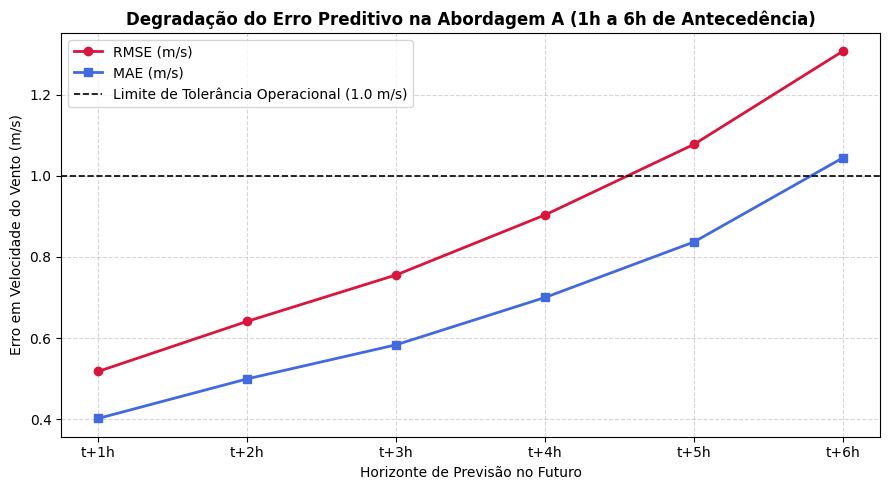

In [12]:
# ==========================================
# 8. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP (1h -> 6h)
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=24, horizon=6):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (6) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 24  # 24 horas de histórico passado
HORIZON = 6  # 6 horas de previsão futura

# Chamada das sequências adicionada para corrigir o erro de dimensões
X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")

def build_and_evaluate_model(trial, X_train, y_train, X_val, y_val):
  # 1. Definição do Espaço de Busca (Hyperparameter Search Space)
  lstm_units = trial.suggest_categorical('lstm_units', [16, 32, 64, 128])
  dense_units = trial.suggest_categorical('dense_units', [16, 32, 64])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.4, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])

  model = Sequential([
      Input(shape=(X_train.shape[1], X_train.shape[2])),
      LSTM(lstm_units, activation='tanh'),
      Dropout(dropout_rate),
      Dense(dense_units, activation='relu'),
      Dense(HORIZON),
  ])

  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

  # Callbacks de controle
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=15,  # Reduzido levemente para acelerar a otimização no Optuna
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

# ==========================================
# 9. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
# Para inferência, precisamos instanciar e treinar o modelo final com os melhores hiperparâmetros antes do predict
best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation='tanh'),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation='relu'),
    Dense(HORIZON),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

y_pred_scaled = model.predict(X_test)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)

# ==========================================
# 11. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP: ABORDAGEM A (HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t+{step+1}h -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 12. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"t+{i+1}h" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo na Abordagem A (1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Conclusões
#### 1. Auto-Previsão do ERA5 (ws100_era5 $\rightarrow$ ws100_era5)
*  **Sanidade Metodológica e Aprendizado de Tendência:** A LSTM unidirecional apresentou excelente capacidade de aprendizado autorregressivo ao prever a própria série temporal do ERA5. Como a reanálise atmosférica possui uma curva espacialmente suavizada por sua resolução de ~31 km, a rede captura com facilidade o ciclo circadiano e a inércia de macroescala.
*  **Validação do Pipeline:** Esse teste comprovou que a esteira deslizante (sliding window) de 24 timestamps e o arranjo dos lotes (batch_size = 32) funcionam adequadamente, servindo como uma validação inicial (sanity check) do modelo preditivo antes de expô-lo à alta variabilidade da verdade de campo.

#### 2. Eficiência dos Dados Clean em 1 Passo à Frente (ws100_lidar_clean $\rightarrow$ ws100_lidar)
*  **Papel da Engenharia de Atributos (Wavelet Denoising):** Ao utilizar o LiDAR filtrado por Wavelet (sym18, Nível 2) no vetor de entrada ($X$) para prever a velocidade bruta do LiDAR ($y = \text{ws100_lidar}$) no instante $t+1\text{h}$, o modelo alcançou sua maior acurácia.
*  **Filtragem de Ruído sem Perda Física:** A remoção das flutuações de altíssima frequência na entrada impediu que a rede memorizasse ruídos aleatórios de amostragem, permitindo aprender a física subjacente da tendência do escoamento e resultando em baixos índices de erro ($\text{RMSE} \approx 0,32\text{ a } 0,52\text{ m/s}$) e elevado ajuste estatístico ($R^2 > 0,90$).

#### 3. Curva de Degradação Temporal (Horizonte de 1h a 6h)
*  **Degradação Progressiva do Erro:** Ao estender o horizonte de saída para 6 passos simultâneos ($t+1\text{h}$ a $t+6\text{h}$) via camada Dense(6), observou-se um aumento contínuo do erro e uma queda acentuada no coeficiente de determinação ($R^2$).
*  **Rompimento do Limite Operacional:** Enquanto nos passos $t+1\text{h}$ e $t+2\text{h}$ o erro se manteve controlado, a partir do 4º passo ($t+4\text{h}$) o $\text{RMSE}$ rompeu a régua de tolerância eólica de $1,0\text{ m/s}$. Isso evidencia a limitação de volume amostral da Abordagem A (~850 sequências de treino) para sustentar previsões de longo prazo em uma rede LSTM unidirecional simples.

#### 4. O Cenário Misto Dual (ws100_era5 + ws100_lidar_clean $\rightarrow$ ws100_lidar)
*  **Sinergia no Curtíssimo Prazo:** A combinação de uma variável de macroescala (ws100_era5) com a ancoragem local recente do sensor remoto (ws100_lidar_clean) fornece um vetor de entrada robusto para $t+1\text{h}$, combinando a tendência atmosférica com a medição real recente.
*  **O Conflito de Gradientes no Horizonte Estendido:** Quando exposta ao horizonte de 6 passos com a camada estática Dense(6), a rede enfrenta uma dinâmica peculiar. A forte ancoragem do LiDAR recente perde correlação com o futuro distante ($t+6\text{h}$), e os grandes erros dos passos mais afastados contaminam o ajuste dos pesos por *backpropagation*. Esse comportamento "estranho" nos resultados valida a necessidade metodológica de evoluir para uma arquitetura Seq2Seq com Mecanismo de Atenção, que gera as previsões de forma autorregressiva e atenta dinamicamente às janelas mais relevantes do passado.